# 质谱工具模块

In [1]:
import time
from typing import Iterable

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

In [4]:
# 全局配置
MZ_MIN = 0.0
MZ_MAX = 1500.0
N_BINS = 10000
BATCH_SIZE = 100_000

In [3]:
# 谱图相关信息
SPECTRUM_COLS = [
    "ms2_mzs",
    "ms2_normalized_intensities",
    "precursor_mz",
    "adduct",
]

In [5]:
# 将质谱图转换为固定长度向量
def spectrum_to_vector(mzs, intensities,
                       mz_min: float = MZ_MIN,
                       mz_max: float = MZ_MAX,
                       n_bins: int = N_BINS) -> np.ndarray:
    vec = np.zeros(n_bins, dtype=np.float32)
    if mzs is None or len(mzs) == 0:
        return vec

    mzs = np.asarray(mzs, dtype=np.float64)
    intensities = np.asarray(intensities, dtype=np.float32)

    bin_idx = ((mzs - mz_min) / (mz_max - mz_min) * n_bins).astype(np.int32)
    bin_idx = np.clip(bin_idx, 0, n_bins - 1)

    # np.maximum.at：散射取最大，同箱多峰取较大值
    np.maximum.at(vec, bin_idx, intensities)
    return vec

In [6]:
mzs = [100.0, 200.0, 300.0]
ints = [0.5, 0.8, 0.3]
vec = spectrum_to_vector(mzs, ints)

print("向量形状:", vec.shape)
print("非零元素:", (vec > 0).sum())
print("非零位置:", np.where(vec > 0)[0])
print("非零值:",   vec[vec > 0])

向量形状: (10000,)
非零元素: 3
非零位置: [ 666 1333 2000]
非零值: [0.5 0.8 0.3]


In [7]:
# 批量向量化 DataFrame
def vectorize_spectra(df: pd.DataFrame,
                      mz_col: str = "ms2_mzs",
                      int_col: str = "ms2_normalized_intensities",
                      desc: str = "谱图",
                      verbose: bool = True) -> np.ndarray:
    n = len(df)
    vecs = np.zeros((n, N_BINS), dtype=np.float32)
    t0 = time.time()

    for i, (mzs, ints) in enumerate(zip(df[mz_col], df[int_col])):
        vecs[i] = spectrum_to_vector(mzs, ints)
        if verbose and (i + 1) % 50000 == 0:
            elapsed = time.time() - t0
            speed = (i + 1) / elapsed
            eta = (n - i - 1) / speed
            print(f"  向量化{desc}: {i+1:,}/{n:,}  "
                  f"({speed:.0f} 张/秒, 剩 {eta:.0f} 秒)", end="\r")

    if verbose:
        print(f"\n  向量化{desc}完成: {n:,} 张，"
              f"用时 {time.time()-t0:.1f} 秒")
    return vecs

In [8]:
# 加载图谱
def load_spectra(path: str,
                 columns: list[str] | None = None,
                 limit: int | None = None,
                 batch_size: int = BATCH_SIZE,
                 verbose: bool = True) -> pd.DataFrame:
    pf = pq.ParquetFile(path)
    parts = []
    total = 0
    t0 = time.time()

    for batch in pf.iter_batches(batch_size=batch_size, columns=columns):
        parts.append(batch.to_pandas())
        total += len(parts[-1])
        if verbose:
            cap = f"/{limit:,}" if limit else ""
            print(f"  加载: {total:,}{cap}", end="\r")
        if limit is not None and total >= limit:
            break

    if verbose:
        print(f"\n  加载完成: {total:,} 行，"
              f"用时 {time.time()-t0:.1f} 秒")

    df = pd.concat(parts, ignore_index=True)
    if limit is not None:
        df = df.head(limit)
    return df

In [9]:
df = load_spectra("../data/enveda_casmi26/train.parquet", limit=100, verbose=False)
print(f"输入: {len(df)} 张谱图")

输入: 100 张谱图


In [10]:
t0 = time.time()
vecs = vectorize_spectra(df, desc="train")
t = time.time() - t0

print(f"\n输出 shape: {vecs.shape}")
print(f"dtype: {vecs.dtype}")
print(f"耗时: {t:.2f} 秒")
print(f"速度: {len(df)/t:.0f} 张/秒")


  向量化train完成: 100 张，用时 0.1 秒

输出 shape: (100, 10000)
dtype: float32
耗时: 0.17 秒
速度: 584 张/秒


In [11]:
# 过滤异常谱图
def filter_valid_spectra(df: pd.DataFrame,
                         prec_min: float = 50.0,
                         prec_max: float = 2000.0,
                         min_peaks: int = 5) -> pd.DataFrame:
    """
    过滤条件：
    1. precursor_mz ∈ [prec_min, prec_max]
    2. min_peaks >= 5
    """
    mask_prec = df["precursor_mz"].between(prec_min, prec_max)
    mask_peaks = df["ms2_mzs"].apply(
        lambda x: x is not None and len(x) >= min_peaks
    )
    return df[mask_prec & mask_peaks].reset_index(drop=True)

In [12]:
filter_vecs = filter_valid_spectra(df)
print(f"\n输出 shape: {filter_vecs.shape}")


输出 shape: (100, 18)


In [17]:
# 按分子分组
def group_by_molecule(df: pd.DataFrame, id_col: str = "inchikey14"):
    """
    1. Usage:
    for mol_id, group in group_by_molecule(train):
        ...
    2. id_col:
    train -> inchikey14
    test -> molecule_id
    """
    return df.groupby(id_col, sort=False)

In [14]:
for mol_id, group in group_by_molecule(df):
    print(f"{mol_id}: {len(group)} 张谱图")

AAALVYBICLMAMA: 1 张谱图
AAKJLRGGTJKAMG: 1 张谱图
AANFHDFOMFRLLR: 1 张谱图
AAOVKJBEBIDNHE: 1 张谱图
ACFIXJIJDZMPPO: 1 张谱图
ACGDKVXYNVEAGU: 1 张谱图
ACNHBCIZLNNLRS: 1 张谱图
ACPOUJIDANTYHO: 1 张谱图
ACRHBAYQBXXRTO: 1 张谱图
ACTIUHUUMQJHFO: 1 张谱图
ACTOXUHEUCPTEW: 1 张谱图
ACWBQPMHZXGDFX: 1 张谱图
ADEBPBSSDYVVLD: 1 张谱图
ADFCQWZHKCXPAJ: 1 张谱图
ADIMAYPTOBDMTL: 1 张谱图
ADVPTQAUNPRNPO: 1 张谱图
AELCINSCMGFISI: 1 张谱图
AEMFNILZOJDQLW: 1 张谱图
AEMOLEFTQBMNLQ: 1 张谱图
AEOCXXJPGCBFJA: 1 张谱图
AEQDJSLRWYMAQI: 1 张谱图
AERBNCYCJBRYDG: 1 张谱图
AEUTYOVWOVBAKS: 1 张谱图
AFCGFAGUEYAMAO: 1 张谱图
AFHJQYHRLPMKHU: 1 张谱图
AFSDNFLWKVMVRB: 1 张谱图
AFZSMODLJJCVPP: 1 张谱图
AGBQKNBQESQNJD: 1 张谱图
AGMMTXLNIQSRCG: 1 张谱图
AGOYDEPGAOXOCK: 1 张谱图
AGPKZVBTJJNPAG: 1 张谱图
AHCYMLUZIRLXAA: 1 张谱图
AHJRHEGDXFFMBM: 1 张谱图
AHLBNYSZXLDEJQ: 1 张谱图
AHLPHDHHMVZTML: 1 张谱图
AHMMSNQYOPMLSX: 1 张谱图
AHOUBRCZNHFOSL: 1 张谱图
AIJULSRZWUXGPQ: 1 张谱图
AIONOLUJZLIMTK: 1 张谱图
AIZFEOPQVZBNGH: 1 张谱图
AJLFOPYRIVGYMJ: 1 张谱图
AJRGHIGYPXNABY: 1 张谱图
AJXPJJZHWIXJCJ: 1 张谱图
AKCRNFFTGXBONI: 1 张谱图
AKNNEGZIBPJZJG: 1 张谱图
AKPLHCDWDR

In [18]:
# 峰筛选
def top_k_peaks(mzs: Iterable[float],
                intensities: Iterable[float],
                k: int = 100) -> tuple[np.ndarray, np.ndarray]:
    mzs = np.asarray(mzs, dtype=np.float64)
    intensities = np.asarray(intensities, dtype=np.float32)

    if len(mzs) <= k:
        order = np.argsort(mzs)
    else:
        idx = np.argsort(intensities)[::-1][:k]
        order = idx[np.argsort(mzs[idx])]

    return mzs[order], intensities[order]

In [21]:
mzs = [100, 200, 300, 400, 500]
ints = [0.1, 0.5, 0.9, 0.3, 0.7]
mz_top, int_top = top_k_peaks(mzs, ints, k=3)

print("原始:")
print(f"  m/z: {mzs}")
print(f"  强度: {ints}")
print()
print("top-3:")
print(f"  m/z: {mz_top}")
print(f"  强度: {int_top}")

原始:
  m/z: [100, 200, 300, 400, 500]
  强度: [0.1, 0.5, 0.9, 0.3, 0.7]

top-3:
  m/z: [200. 300. 500.]
  强度: [0.5 0.9 0.7]


In [22]:
# 谱图可视化
def plot_spectrum_from_row(row, ax=None,
                           title: str | None = None,
                           top_k: int | None = None):
    mzs = np.asarray(row["ms2_mzs"])
    intens = np.asarray(row["ms2_normalized_intensities"])

    if top_k is not None:
        mzs, intens = top_k_peaks(mzs, intens, k=top_k)

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))

    ax.vlines(mzs, 0, intens, colors="steelblue", linewidth=1.2)
    ax.set_xlabel("m/z")
    ax.set_ylabel("Normalized Intensity")
    ax.set_xlim(MZ_MIN, MZ_MAX)

    if title is None:
        p = row.get("precursor_mz", None)
        title = f"precursor_mz={p:.4f}" if p is not None else "MS/MS"
        if "adduct" in row and row["adduct"] is not None:
            title += f"  adduct={row['adduct']}"
    ax.set_title(title)
    ax.grid(alpha=0.3)
    return ax

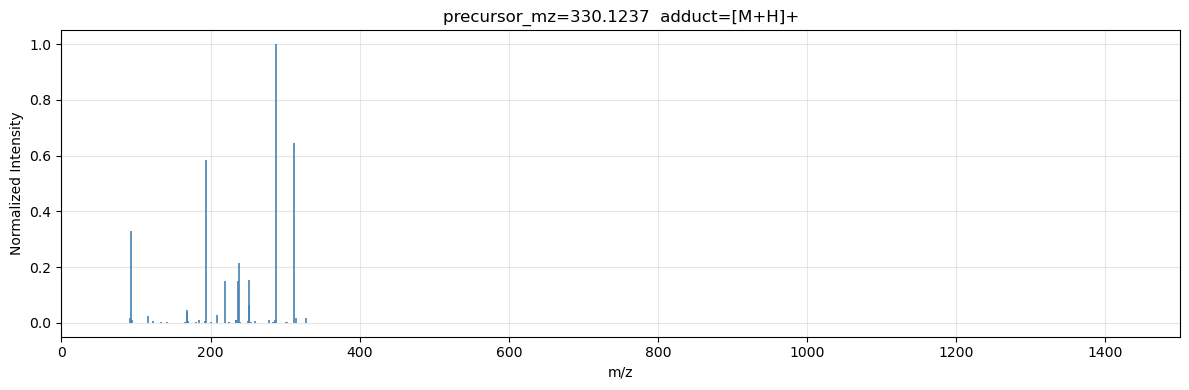

In [23]:
df = load_spectra("../data/enveda_casmi26/train.parquet", limit=5, verbose=False)
fig, ax = plt.subplots(figsize=(12, 4))
plot_spectrum_from_row(df.iloc[0], ax=ax, top_k=50)
plt.tight_layout()
plt.show()

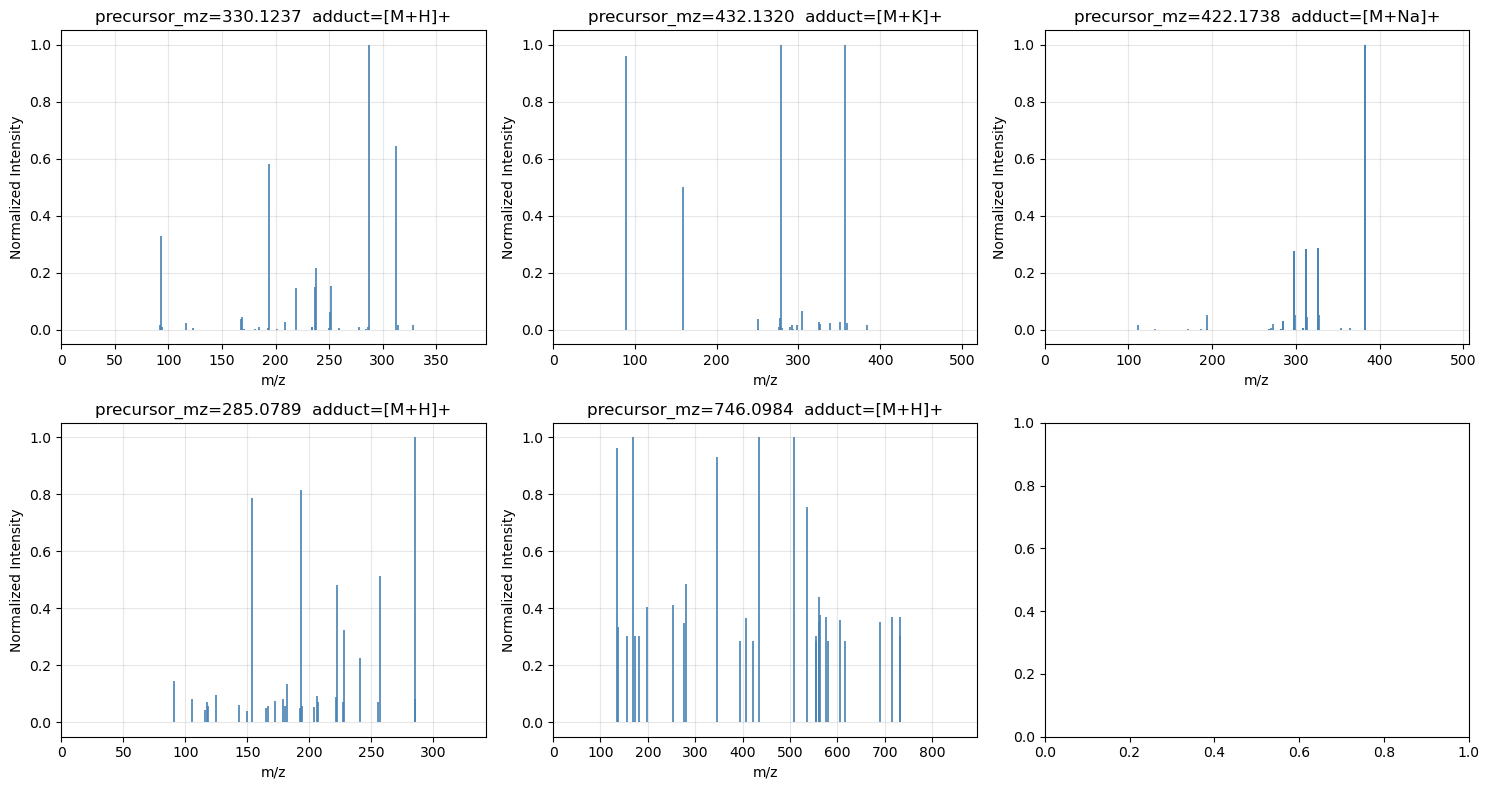

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (_, row) in enumerate(df.head(6).iterrows()):
    ax = axes[i // 3, i % 3]
    plot_spectrum_from_row(row, ax=ax, top_k=30)
    ax.set_xlim(0, row["precursor_mz"] * 1.2)
plt.tight_layout()
plt.show()